In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
insurance=pd.read_csv("new_insurance_data.csv")

In [3]:
insurance

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,18.0,male,23.210,0.0,no,29087.54313,17.0,715428.0,4.720921e+06,0.0,5.578497e+07,southeast,1121.87390
1,18.0,male,30.140,0.0,no,39053.67437,7.0,699157.0,4.329832e+06,0.0,1.370089e+07,southeast,1131.50660
2,18.0,male,33.330,0.0,no,39023.62759,19.0,702341.0,6.884861e+06,0.0,7.352311e+07,southeast,1135.94070
3,18.0,male,33.660,0.0,no,28185.39332,11.0,700250.0,4.274774e+06,0.0,7.581968e+07,southeast,1136.39940
4,18.0,male,34.100,0.0,no,14697.85941,16.0,711584.0,3.787294e+06,0.0,2.301232e+07,southeast,1137.01100
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,33.0,female,35.530,0.0,yes,63142.25346,32.0,1091267.0,1.703805e+08,2.0,3.101107e+09,northwest,55135.40209
1334,31.0,female,38.095,1.0,yes,43419.95227,31.0,1107872.0,2.015152e+08,2.0,3.484216e+09,northeast,58571.07448
1335,52.0,male,34.485,3.0,yes,52458.92353,25.0,1092005.0,2.236450e+08,2.0,3.640807e+09,northwest,60021.39897
1336,45.0,male,30.360,0.0,yes,69927.51664,34.0,1106821.0,2.528924e+08,3.0,4.006359e+09,southeast,62592.87309


## 1.Basic checks

In [4]:
insurance.shape

(1338, 13)

In [5]:
insurance.describe()

,age,bmi,children,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,charges
count,1329.000000,1335.000000,1333.000000,1324.000000,1332.000000,1.335000e+03,1.334000e+03,1336.000000,1.332000e+03,1338.000000
mean,39.310008,30.665112,1.090773,33361.327180,15.216216,9.100047e+05,1.584179e+07,1.060629,3.696849e+08,13270.422265
std,14.034818,6.101690,1.201856,15617.288337,7.467723,9.188612e+04,2.669305e+07,0.533583,5.668843e+08,12110.011237
min,18.000000,15.960000,0.000000,1920.136268,1.000000,6.954300e+05,2.945253e+04,0.000000,2.747072e+06,1121.873900
25%,27.000000,26.302500,0.000000,20768.860390,9.000000,8.471995e+05,4.077633e+06,1.000000,7.701932e+07,4740.287150
50%,39.000000,30.400000,1.000000,33700.310675,15.000000,9.143000e+05,7.490337e+06,1.000000,1.419361e+08,9382.033000
75%,51.000000,34.687500,2.000000,45052.331957,20.000000,9.716840e+05,1.084082e+07,1.000000,3.243499e+08,16639.912515
max,64.000000,53.130000,5.000000,77277.988480,40.000000,1.107872e+06,2.616317e+08,3.000000,4.117197e+09,63770.428010


In [6]:
insurance.head()

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,18.0,male,23.21,0.0,no,29087.54313,17.0,715428.0,4720920.992,0.0,55784970.05,southeast,1121.8739
1,18.0,male,30.14,0.0,no,39053.67437,7.0,699157.0,4329831.676,0.0,13700885.19,southeast,1131.5066
2,18.0,male,33.33,0.0,no,39023.62759,19.0,702341.0,6884860.774,0.0,73523107.27,southeast,1135.9407
3,18.0,male,33.66,0.0,no,28185.39332,11.0,700250.0,4274773.550,0.0,75819679.60,southeast,1136.3994
4,18.0,male,34.10,0.0,no,14697.85941,16.0,711584.0,3787293.921,0.0,23012320.01,southeast,1137.0110


In [7]:
insurance.tail()

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
1333,33.0,female,35.530,0.0,yes,63142.25346,32.0,1091267.0,170380500.5,2.0,3.101107e+09,northwest,55135.40209
1334,31.0,female,38.095,1.0,yes,43419.95227,31.0,1107872.0,201515184.8,2.0,3.484216e+09,northeast,58571.07448
1335,52.0,male,34.485,3.0,yes,52458.92353,25.0,1092005.0,223644981.3,2.0,3.640807e+09,northwest,60021.39897
1336,45.0,male,30.360,0.0,yes,69927.51664,34.0,1106821.0,252892382.6,3.0,4.006359e+09,southeast,62592.87309
1337,54.0,female,47.410,0.0,yes,63982.80926,31.0,1100328.0,261631699.3,3.0,4.117197e+09,southeast,63770.42801


In [8]:
insurance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 13 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   age                              1329 non-null   float64
 1   sex                              1338 non-null   object 
 2   bmi                              1335 non-null   float64
 3   children                         1333 non-null   float64
 4   smoker                           1338 non-null   object 
 5   Claim_Amount                     1324 non-null   float64
 6   past_consultations               1332 non-null   float64
 7   num_of_steps                     1335 non-null   float64
 8   Hospital_expenditure             1334 non-null   float64
 9   NUmber_of_past_hospitalizations  1336 non-null   float64
 10  Anual_Salary                     1332 non-null   float64
 11  region                           1338 non-null   object 
 12  charges             

In [9]:
insurance.describe(include='O')

,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


In [10]:
insurance.isnull().sum()

age                                 9
sex                                 0
bmi                                 3
children                            5
smoker                              0
Claim_Amount                       14
past_consultations                  6
num_of_steps                        3
Hospital_expenditure                4
NUmber_of_past_hospitalizations     2
Anual_Salary                        6
region                              0
charges                             0
dtype: int64

In [11]:
insurance.isnull()

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,False,False,False,False,False,False,False,False,False,False,False,False,False
1334,False,False,False,False,False,False,False,False,False,False,False,False,False
1335,False,False,False,False,False,False,False,False,False,False,False,False,False
1336,False,False,False,False,False,False,False,False,False,False,False,False,False


## 2. EDA(exploratory data analysis)

In [12]:
insurance.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'Claim_Amount',
       'past_consultations', 'num_of_steps', 'Hospital_expenditure',
       'NUmber_of_past_hospitalizations', 'Anual_Salary', 'region', 'charges'],
      dtype='object')

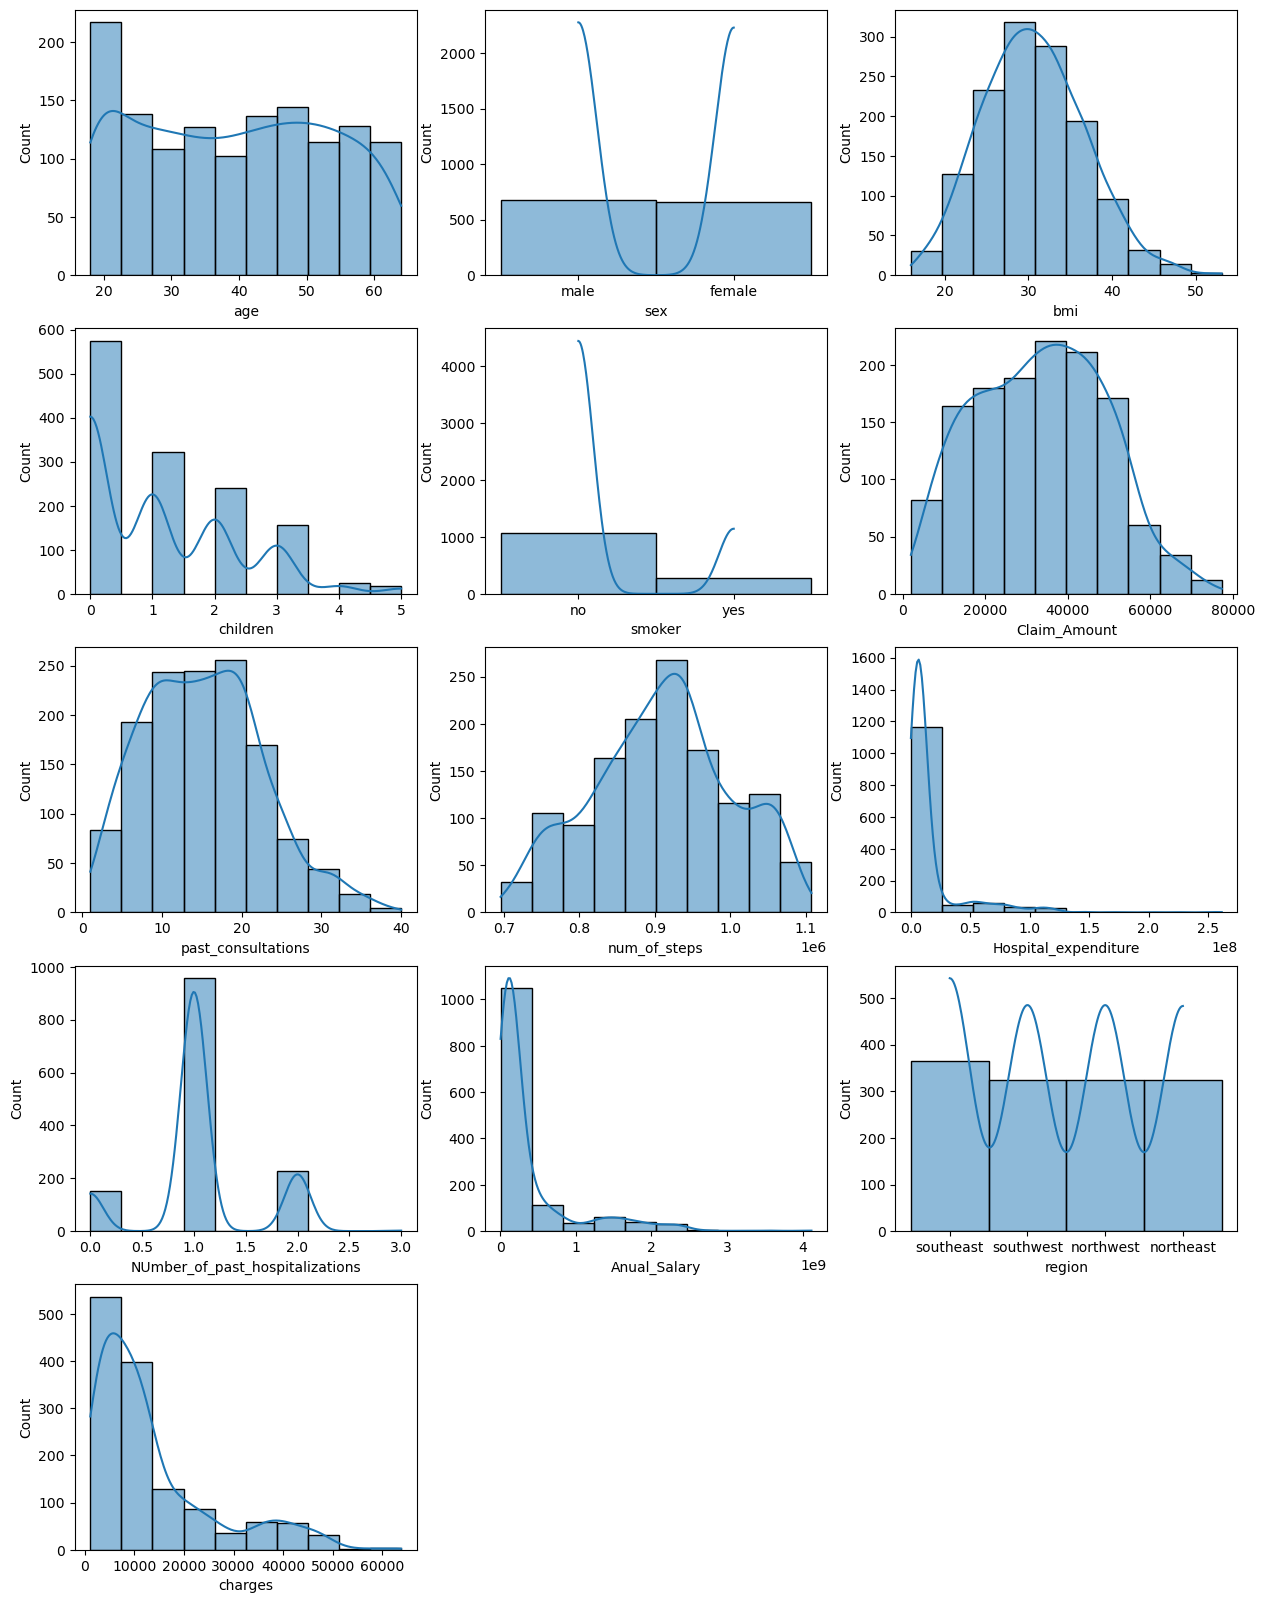

In [13]:
#univariant analysis
plt.figure(figsize=(15,20))
pos=1
for i in insurance.columns:
    plt.subplot(5,3,pos)
    sns.histplot(insurance[i],bins=10,kde=True)
    pos=pos+1

<Axes: xlabel='Anual_Salary', ylabel='charges'>

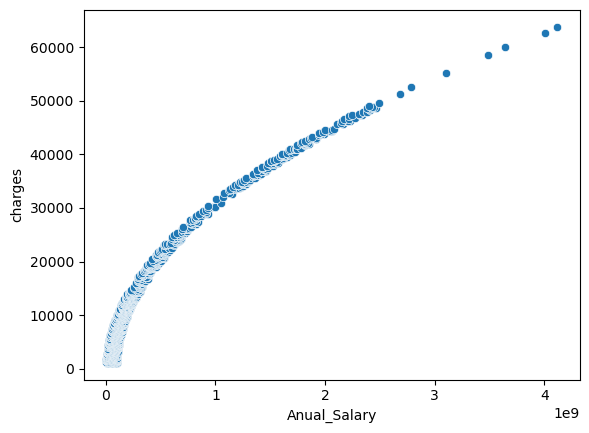

In [14]:
#bivariate Analysis
sns.scatterplot(x=insurance['Anual_Salary'],y=insurance['charges'])

<Axes: xlabel='Anual_Salary', ylabel='charges'>

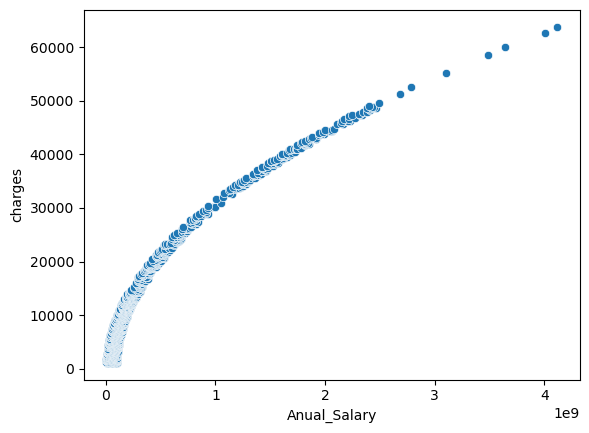

In [15]:
sns.scatterplot(x='Anual_Salary',y='charges',data=insurance)

In [16]:
num=insurance.select_dtypes(exclude='O').columns
num

Index(['age', 'bmi', 'children', 'Claim_Amount', 'past_consultations',
       'num_of_steps', 'Hospital_expenditure',
       'NUmber_of_past_hospitalizations', 'Anual_Salary', 'charges'],
      dtype='object')

In [17]:
insurance[num].corr()

,age,bmi,children,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,charges
age,1.000000,0.112849,0.041558,0.123430,0.169275,0.517930,0.136930,0.363041,0.164328,0.294390
bmi,0.112849,1.000000,0.007944,0.093893,0.131246,0.136368,0.257141,0.137575,0.241941,0.198794
children,0.041558,0.007944,1.000000,0.041778,0.054787,0.163522,0.025150,0.185607,0.040070,0.070747
Claim_Amount,0.123430,0.093893,0.041778,1.000000,0.273779,0.400672,0.374159,0.381152,0.409268,0.439161
past_consultations,0.169275,0.131246,0.054787,0.273779,1.000000,0.562344,0.544640,0.503798,0.596322,0.629836
num_of_steps,0.517930,0.136368,0.163522,0.400672,0.562344,1.000000,0.626659,0.850089,0.739426,0.890642
Hospital_expenditure,0.136930,0.257141,0.025150,0.374159,0.544640,0.626659,1.000000,0.657247,0.969695,0.874079
NUmber_of_past_hospitalizations,0.363041,0.137575,0.185607,0.381152,0.503798,0.850089,0.657247,1.000000,0.743466,0.823581
Anual_Salary,0.164328,0.241941,0.040070,0.409268,0.596322,0.739426,0.969695,0.743466,1.000000,0.954255
charges,0.294390,0.198794,0.070747,0.439161,0.629836,0.890642,0.874079,0.823581,0.954255,1.000000


## 3. Data preprocessing and feature Engineering

In [18]:
#1.Handling missing datas
#2.checking duplicates
#3.checking outliers
#4.Encoding
#5.Scaling
#6.balancing technique
#7.transformation(optional)

In [19]:
insurance.isnull().sum()

age                                 9
sex                                 0
bmi                                 3
children                            5
smoker                              0
Claim_Amount                       14
past_consultations                  6
num_of_steps                        3
Hospital_expenditure                4
NUmber_of_past_hospitalizations     2
Anual_Salary                        6
region                              0
charges                             0
dtype: int64

In [20]:
col=insurance.columns
col

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'Claim_Amount',
       'past_consultations', 'num_of_steps', 'Hospital_expenditure',
       'NUmber_of_past_hospitalizations', 'Anual_Salary', 'region', 'charges'],
      dtype='object')

In [21]:
#numeric datas-replace with mean/median we go with median(normalization we apply mean,skewness go with median)
insurance["age"].median()

39.0

In [22]:
#categorical datas- we replace with mode 
insurance["smoker"].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [23]:
#with index it is showing to avoid it we go with indexing 
insurance['smoker'].mode()

0    no
Name: smoker, dtype: object

In [24]:
insurance['smoker'].mode()[0]

'no'

In [25]:
for col_name in col:
    if insurance[col_name].dtypes=='object':
        insurance[col_name]=insurance[col_name].fillna(insurance[col_name].mode()[0])
    else:
        insurance[col_name]=insurance[col_name].fillna(insurance[col_name].median())

In [26]:
insurance.isnull().sum()

age                                0
sex                                0
bmi                                0
children                           0
smoker                             0
Claim_Amount                       0
past_consultations                 0
num_of_steps                       0
Hospital_expenditure               0
NUmber_of_past_hospitalizations    0
Anual_Salary                       0
region                             0
charges                            0
dtype: int64

In [27]:
insurance.duplicated().sum()

0

In [28]:
#if duplicate is present in dataset
#insurance.drop_duplicates(inplace=True)

In [29]:
col1=insurance.select_dtypes(exclude='O').columns
col1

Index(['age', 'bmi', 'children', 'Claim_Amount', 'past_consultations',
       'num_of_steps', 'Hospital_expenditure',
       'NUmber_of_past_hospitalizations', 'Anual_Salary', 'charges'],
      dtype='object')

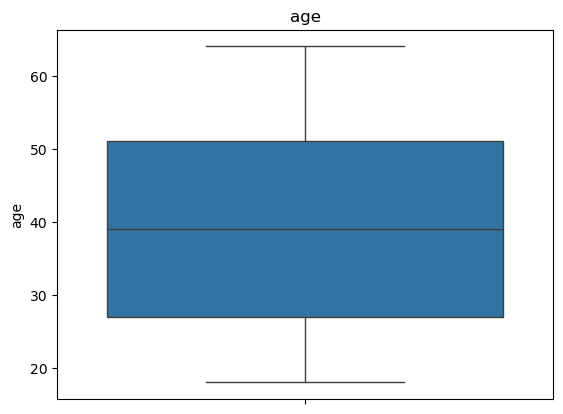

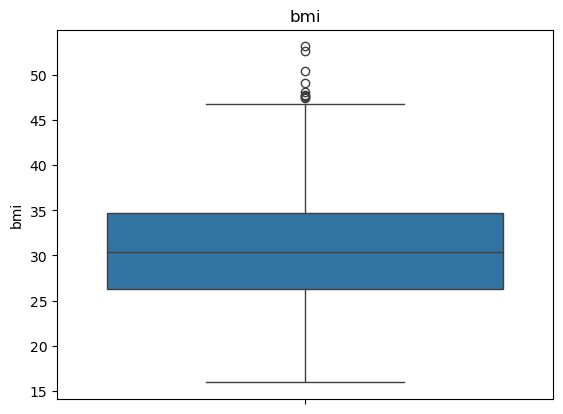

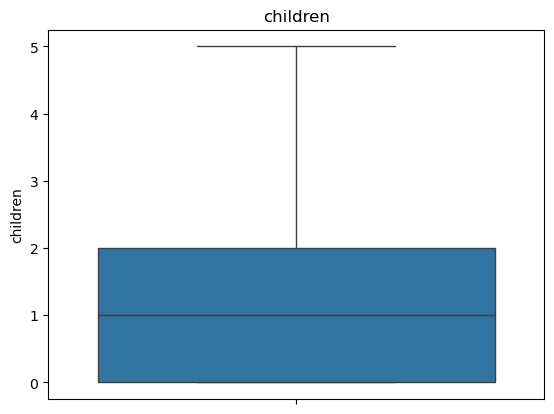

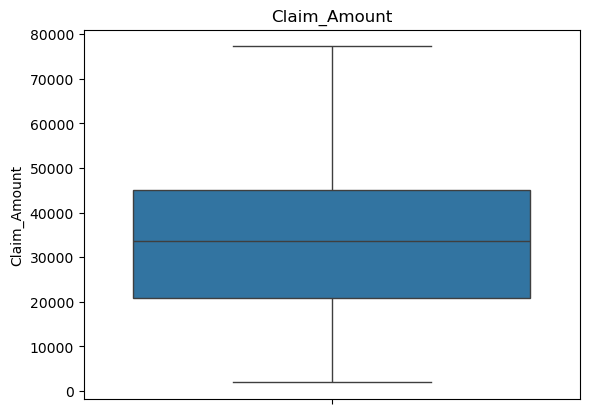

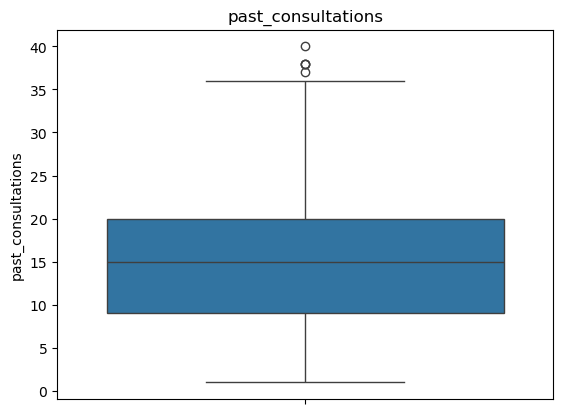

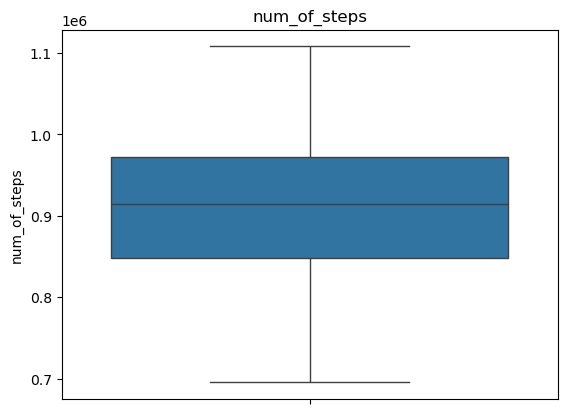

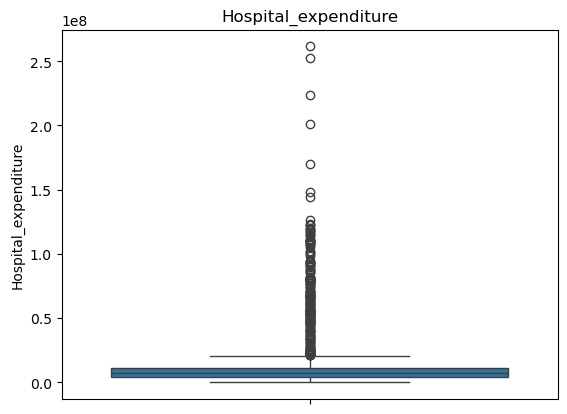

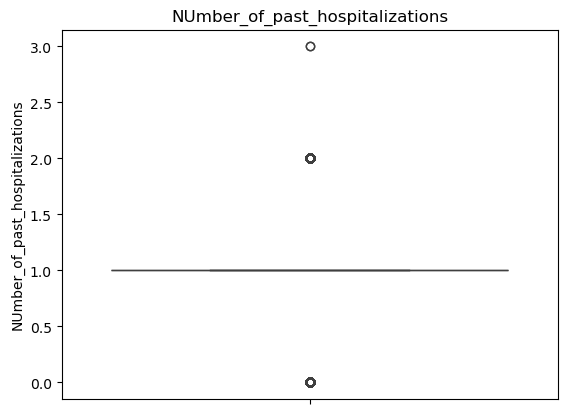

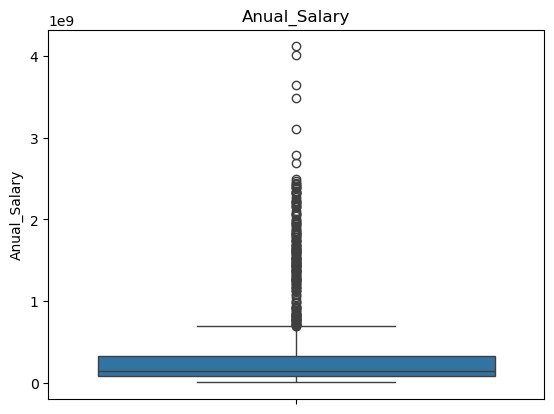

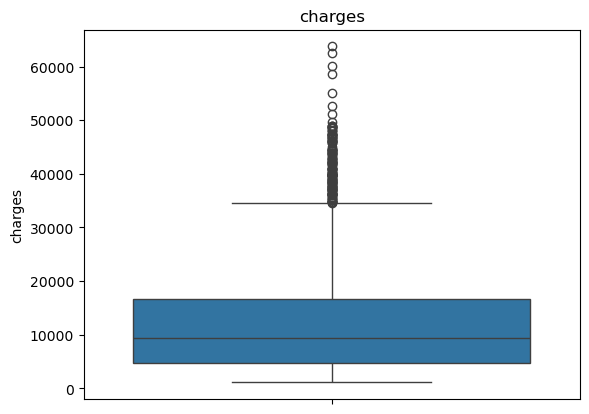

In [30]:
for col_name in col1:
    sns.boxplot(insurance[col_name])
    plt.title(col_name)
    plt.show()

In [31]:
# 4.Encoding

In [32]:
#encoding-converting categorical columns to numeric 
#encoder of two types:
#1.nominal encoder-->categorical data without any order value--important
#two types in nominal encoder-->label encoder and one Hot encoder
#2.ordinal encoder-->categorical data that follow order

In [33]:
#label encoder-->assign unique integers for distinct categories in an alphabetical way ex.female-0 male-1
#One Hot Encoder(OHE)-->creates a sparx matrix with activated or deactivated

In [34]:
col2=insurance.select_dtypes(include='O').columns
col2

Index(['sex', 'smoker', 'region'], dtype='object')

In [35]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
for i in col2:
    insurance[i]=le.fit_transform(insurance[i]) #fit_transform-->learn and apply
insurance

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,18.0,1,23.210,0.0,0,29087.54313,17.0,715428.0,4.720921e+06,0.0,5.578497e+07,2,1121.87390
1,18.0,1,30.140,0.0,0,39053.67437,7.0,699157.0,4.329832e+06,0.0,1.370089e+07,2,1131.50660
2,18.0,1,33.330,0.0,0,39023.62759,19.0,702341.0,6.884861e+06,0.0,7.352311e+07,2,1135.94070
3,18.0,1,33.660,0.0,0,28185.39332,11.0,700250.0,4.274774e+06,0.0,7.581968e+07,2,1136.39940
4,18.0,1,34.100,0.0,0,14697.85941,16.0,711584.0,3.787294e+06,0.0,2.301232e+07,2,1137.01100
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,33.0,0,35.530,0.0,1,63142.25346,32.0,1091267.0,1.703805e+08,2.0,3.101107e+09,1,55135.40209
1334,31.0,0,38.095,1.0,1,43419.95227,31.0,1107872.0,2.015152e+08,2.0,3.484216e+09,0,58571.07448
1335,52.0,1,34.485,3.0,1,52458.92353,25.0,1092005.0,2.236450e+08,2.0,3.640807e+09,1,60021.39897
1336,45.0,1,30.360,0.0,1,69927.51664,34.0,1106821.0,2.528924e+08,3.0,4.006359e+09,2,62592.87309


In [36]:
#5.Scaling
#confines the numeric data in a simpler format
#Min max scaler-scales the data to [0-1] , N=x-xmin/xmax-xmin (for skewed distriution)
#standard scaler-scales the data b/w [-3,3] , z-score=x-u/std (for normal distribution)

In [37]:
from sklearn.preprocessing import MinMaxScaler
mm=MinMaxScaler()
for i in insurance.columns:
    insurance[[i]]=mm.fit_transform(insurance[[i]]) #result will be in format nested list so to change to table [[]] 

In [38]:
insurance

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,0.000000,1.0,0.195050,0.0,0.0,0.360512,0.410256,0.048487,0.017934,0.000000,0.012891,0.666667,0.000000
1,0.000000,1.0,0.381490,0.0,0.0,0.492763,0.153846,0.009036,0.016439,0.000000,0.002662,0.666667,0.000154
2,0.000000,1.0,0.467312,0.0,0.0,0.492364,0.461538,0.016756,0.026205,0.000000,0.017202,0.666667,0.000225
3,0.000000,1.0,0.476190,0.0,0.0,0.348540,0.256410,0.011686,0.016228,0.000000,0.017760,0.666667,0.000232
4,0.000000,1.0,0.488028,0.0,0.0,0.169561,0.384615,0.039167,0.014365,0.000000,0.004925,0.666667,0.000242
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,0.326087,0.0,0.526500,0.0,1.0,0.812419,0.794872,0.959740,0.651183,0.666667,0.753044,0.333333,0.862167
1334,0.282609,0.0,0.595507,0.2,1.0,0.550703,0.769231,1.000000,0.770199,0.666667,0.846157,0.000000,0.917008
1335,0.739130,1.0,0.498386,0.6,1.0,0.670651,0.615385,0.961529,0.854792,0.666667,0.884215,0.333333,0.940158
1336,0.586957,1.0,0.387409,0.0,1.0,0.902459,0.846154,0.997452,0.966593,1.000000,0.973061,0.666667,0.981204


## 4.Feature Selection

In [39]:
#correlation(numeric_only is used to directly retrive the correlation values as all the values are converted to numeric)
res1=insurance.corr(numeric_only=True)
res1

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
age,1.000000,-0.019154,0.112174,0.041710,-0.028792,0.122873,0.168479,0.513066,0.137208,0.359637,0.163478,0.004623,0.293735
sex,-0.019154,1.000000,0.045138,0.018533,0.076185,-0.003821,0.050274,0.010445,0.069940,0.000214,0.072702,0.004588,0.057292
bmi,0.112174,0.045138,1.000000,0.007790,0.003659,0.093447,0.130701,0.135994,0.256924,0.137115,0.241550,0.158218,0.198745
children,0.041710,0.018533,0.007790,1.000000,0.009608,0.041607,0.054806,0.163478,0.025315,0.185546,0.041260,0.015011,0.070877
smoker,-0.028792,0.076185,0.003659,0.009608,1.000000,0.334410,0.502794,0.665656,0.662698,0.588682,0.739676,-0.002181,0.787251
Claim_Amount,0.122873,-0.003821,0.093447,0.041607,0.334410,1.000000,0.271526,0.398285,0.369988,0.379923,0.404026,0.009098,0.435671
past_consultations,0.168479,0.050274,0.130701,0.054806,0.502794,0.271526,1.000000,0.559692,0.542150,0.500145,0.589292,-0.001864,0.627598
num_of_steps,0.513066,0.010445,0.135994,0.163478,0.665656,0.398285,0.559692,1.000000,0.624790,0.844983,0.733622,-0.041938,0.889753
Hospital_expenditure,0.137208,0.069940,0.256924,0.025315,0.662698,0.369988,0.542150,0.624790,1.000000,0.651827,0.957189,0.029446,0.871796
NUmber_of_past_hospitalizations,0.359637,0.000214,0.137115,0.185546,0.588682,0.379923,0.500145,0.844983,0.651827,1.000000,0.735802,-0.031450,0.820682


In [40]:
#Multicollinearity-->Identifies the relantionship b/w independent features such that relantionship shouldn't be greater than 80%
res=insurance[insurance.columns[:-1]].corr()
res #eliminate the target column

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region
age,1.000000,-0.019154,0.112174,0.041710,-0.028792,0.122873,0.168479,0.513066,0.137208,0.359637,0.163478,0.004623
sex,-0.019154,1.000000,0.045138,0.018533,0.076185,-0.003821,0.050274,0.010445,0.069940,0.000214,0.072702,0.004588
bmi,0.112174,0.045138,1.000000,0.007790,0.003659,0.093447,0.130701,0.135994,0.256924,0.137115,0.241550,0.158218
children,0.041710,0.018533,0.007790,1.000000,0.009608,0.041607,0.054806,0.163478,0.025315,0.185546,0.041260,0.015011
smoker,-0.028792,0.076185,0.003659,0.009608,1.000000,0.334410,0.502794,0.665656,0.662698,0.588682,0.739676,-0.002181
Claim_Amount,0.122873,-0.003821,0.093447,0.041607,0.334410,1.000000,0.271526,0.398285,0.369988,0.379923,0.404026,0.009098
past_consultations,0.168479,0.050274,0.130701,0.054806,0.502794,0.271526,1.000000,0.559692,0.542150,0.500145,0.589292,-0.001864
num_of_steps,0.513066,0.010445,0.135994,0.163478,0.665656,0.398285,0.559692,1.000000,0.624790,0.844983,0.733622,-0.041938
Hospital_expenditure,0.137208,0.069940,0.256924,0.025315,0.662698,0.369988,0.542150,0.624790,1.000000,0.651827,0.957189,0.029446
NUmber_of_past_hospitalizations,0.359637,0.000214,0.137115,0.185546,0.588682,0.379923,0.500145,0.844983,0.651827,1.000000,0.735802,-0.031450


In [41]:
res[res>0.8]

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region
age,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
children,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoker,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Claim_Amount,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN
past_consultations,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
num_of_steps,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,0.844983,NaN,NaN
Hospital_expenditure,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,0.957189,NaN
NUmber_of_past_hospitalizations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.844983,NaN,1.000000,NaN,NaN


In [42]:
#1.drop features 
insurance.drop('num_of_steps',axis=1,inplace=True)

In [43]:
res=insurance[insurance.columns[:-1]].corr()
res

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region
age,1.000000,-0.019154,0.112174,0.041710,-0.028792,0.122873,0.168479,0.137208,0.359637,0.163478,0.004623
sex,-0.019154,1.000000,0.045138,0.018533,0.076185,-0.003821,0.050274,0.069940,0.000214,0.072702,0.004588
bmi,0.112174,0.045138,1.000000,0.007790,0.003659,0.093447,0.130701,0.256924,0.137115,0.241550,0.158218
children,0.041710,0.018533,0.007790,1.000000,0.009608,0.041607,0.054806,0.025315,0.185546,0.041260,0.015011
smoker,-0.028792,0.076185,0.003659,0.009608,1.000000,0.334410,0.502794,0.662698,0.588682,0.739676,-0.002181
Claim_Amount,0.122873,-0.003821,0.093447,0.041607,0.334410,1.000000,0.271526,0.369988,0.379923,0.404026,0.009098
past_consultations,0.168479,0.050274,0.130701,0.054806,0.502794,0.271526,1.000000,0.542150,0.500145,0.589292,-0.001864
Hospital_expenditure,0.137208,0.069940,0.256924,0.025315,0.662698,0.369988,0.542150,1.000000,0.651827,0.957189,0.029446
NUmber_of_past_hospitalizations,0.359637,0.000214,0.137115,0.185546,0.588682,0.379923,0.500145,0.651827,1.000000,0.735802,-0.031450
Anual_Salary,0.163478,0.072702,0.241550,0.041260,0.739676,0.404026,0.589292,0.957189,0.735802,1.000000,0.015843


In [44]:
res[res>0.8]

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region
age,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
children,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoker,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN
Claim_Amount,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
past_consultations,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN
Hospital_expenditure,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,0.957189,NaN
NUmber_of_past_hospitalizations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN
Anual_Salary,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.957189,NaN,1.000000,NaN


In [45]:
#2.new features
#VIF-varaince inflation factor-->measures degree of multicollinearity

In [46]:
x=insurance[insurance.columns[:-1]]
y=insurance['charges']

In [47]:
x.shape

(1338, 11)

In [48]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_df=pd.DataFrame({
    "Feature":x.columns,
    "VIF":[variance_inflation_factor(x.values,i)
           for i in range(x.shape[1])]
})
print(vif_df.sort_values("VIF",ascending=False))

                            Feature        VIF
9                      Anual_Salary  26.043543
7              Hospital_expenditure  18.042247
8   NUmber_of_past_hospitalizations  12.627577
6                past_consultations   6.553519
2                               bmi   6.206092
5                      Claim_Amount   5.474138
0                               age   4.283659
4                            smoker   3.445088
10                           region   2.805293
3                          children   1.943851
1                               sex   1.939201


In [49]:
x['salary_yo_expense_ratio']=x['Hospital_expenditure']/(x['Anual_Salary']+1)
x

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,salary_yo_expense_ratio
0,0.000000,1.0,0.195050,0.0,0.0,0.360512,0.410256,0.017934,0.000000,0.012891,0.666667,0.017705
1,0.000000,1.0,0.381490,0.0,0.0,0.492763,0.153846,0.016439,0.000000,0.002662,0.666667,0.016395
2,0.000000,1.0,0.467312,0.0,0.0,0.492364,0.461538,0.026205,0.000000,0.017202,0.666667,0.025762
3,0.000000,1.0,0.476190,0.0,0.0,0.348540,0.256410,0.016228,0.000000,0.017760,0.666667,0.015945
4,0.000000,1.0,0.488028,0.0,0.0,0.169561,0.384615,0.014365,0.000000,0.004925,0.666667,0.014294
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,0.326087,0.0,0.526500,0.0,1.0,0.812419,0.794872,0.651183,0.666667,0.753044,0.333333,0.371459
1334,0.282609,0.0,0.595507,0.2,1.0,0.550703,0.769231,0.770199,0.666667,0.846157,0.000000,0.417190
1335,0.739130,1.0,0.498386,0.6,1.0,0.670651,0.615385,0.854792,0.666667,0.884215,0.333333,0.453659
1336,0.586957,1.0,0.387409,0.0,1.0,0.902459,0.846154,0.966593,1.000000,0.973061,0.666667,0.489895


In [50]:
x.drop(['Anual_Salary','Hospital_expenditure'],axis=1,inplace=True)

In [51]:
res2=x.corr()
res2

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,NUmber_of_past_hospitalizations,region,salary_yo_expense_ratio
age,1.000000,-0.019154,0.112174,0.041710,-0.028792,0.122873,0.168479,0.359637,0.004623,0.141932
sex,-0.019154,1.000000,0.045138,0.018533,0.076185,-0.003821,0.050274,0.000214,0.004588,0.074866
bmi,0.112174,0.045138,1.000000,0.007790,0.003659,0.093447,0.130701,0.137115,0.158218,0.253908
children,0.041710,0.018533,0.007790,1.000000,0.009608,0.041607,0.054806,0.185546,0.015011,0.025445
smoker,-0.028792,0.076185,0.003659,0.009608,1.000000,0.334410,0.502794,0.588682,-0.002181,0.698404
Claim_Amount,0.122873,-0.003821,0.093447,0.041607,0.334410,1.000000,0.271526,0.379923,0.009098,0.383157
past_consultations,0.168479,0.050274,0.130701,0.054806,0.502794,0.271526,1.000000,0.500145,-0.001864,0.563831
NUmber_of_past_hospitalizations,0.359637,0.000214,0.137115,0.185546,0.588682,0.379923,0.500145,1.000000,-0.031450,0.684990
region,0.004623,0.004588,0.158218,0.015011,-0.002181,0.009098,-0.001864,-0.031450,1.000000,0.029975
salary_yo_expense_ratio,0.141932,0.074866,0.253908,0.025445,0.698404,0.383157,0.563831,0.684990,0.029975,1.000000


In [52]:
res2[res2>0.8]

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,NUmber_of_past_hospitalizations,region,salary_yo_expense_ratio
age,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
children,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN
smoker,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
Claim_Amount,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN
past_consultations,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN
NUmber_of_past_hospitalizations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN
region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN
salary_yo_expense_ratio,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0


## 5.Model Creation

In [53]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [54]:
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.75,random_state=42)

In [55]:
x_train #training state

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,NUmber_of_past_hospitalizations,region,salary_yo_expense_ratio
693,0.739130,1.0,0.383105,0.2,0.0,0.154089,0.564103,0.333333,1.000000,0.018830
1297,0.086957,1.0,0.985203,0.2,1.0,0.744440,0.641026,0.666667,0.666667,0.240601
634,0.608696,0.0,0.477939,0.2,0.0,0.194139,0.102564,0.333333,0.000000,0.034312
1022,0.326087,1.0,0.237692,0.0,1.0,0.713724,0.641026,0.333333,0.000000,0.028632
178,0.021739,1.0,0.125235,0.4,0.0,0.584708,0.333333,0.333333,0.333333,0.000105
...,...,...,...,...,...,...,...,...,...,...
1095,0.891304,1.0,0.576809,0.0,0.0,0.605567,0.461538,0.333333,1.000000,0.037984
1130,0.608696,1.0,0.313156,0.0,0.0,0.819449,0.333333,0.666667,1.000000,0.075767
1294,0.782609,1.0,0.490987,0.4,1.0,0.539537,0.589744,0.666667,0.666667,0.234915
860,0.869565,0.0,0.552058,0.0,0.0,0.337707,0.538462,0.333333,0.333333,0.013186


In [56]:
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.75,random_state=24)

In [57]:
x_train

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,NUmber_of_past_hospitalizations,region,salary_yo_expense_ratio
478,0.434783,1.0,0.138822,0.6,0.0,0.521024,0.358974,0.333333,0.666667,0.031973
1242,0.282609,1.0,0.547215,0.4,1.0,0.391910,0.743590,0.666667,1.000000,0.187150
1113,0.217391,0.0,0.224913,0.2,0.0,0.534136,0.641026,0.666667,0.000000,0.043652
1223,0.891304,0.0,0.506860,0.4,0.0,0.794575,0.666667,0.666667,1.000000,0.151788
1251,0.195652,1.0,0.704062,0.0,1.0,0.376571,0.435897,0.666667,0.666667,0.189585
...,...,...,...,...,...,...,...,...,...,...
145,0.130435,0.0,0.485069,0.0,0.0,0.450035,0.333333,0.000000,0.666667,0.023692
343,0.195652,1.0,0.079231,0.6,0.0,0.421723,0.256410,0.333333,0.000000,0.002377
192,0.130435,0.0,0.250471,0.0,0.0,0.165942,0.461538,0.333333,0.000000,0.036103
899,0.956522,1.0,0.146355,0.0,0.0,0.545167,0.282051,0.333333,1.000000,0.035517


In [58]:
y_train 

478     0.088281
1242    0.600000
1113    0.353832
1223    0.571262
1251    0.614378
          ...   
145     0.021572
343     0.059156
192     0.030684
899     0.188915
418     0.076443
Name: charges, Length: 1003, dtype: float64

In [59]:
x_test #testing

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,NUmber_of_past_hospitalizations,region,salary_yo_expense_ratio
736,0.782609,1.0,0.452381,0.0,0.0,0.688366,0.384615,0.333333,0.000000,0.017745
561,0.565217,1.0,0.568738,0.4,0.0,0.104786,0.282051,0.333333,1.000000,0.002908
930,0.956522,1.0,0.434490,0.0,0.0,0.251398,0.358974,0.333333,0.000000,0.034546
271,0.239130,1.0,0.350148,0.2,0.0,0.353241,0.025641,0.333333,0.000000,0.033683
933,0.934783,0.0,0.536723,0.0,0.0,0.625146,0.128205,0.333333,0.000000,0.024492
...,...,...,...,...,...,...,...,...,...,...
799,0.869565,1.0,0.592951,0.0,0.0,0.424284,0.512821,0.333333,1.000000,0.038556
1065,0.347826,1.0,0.319478,0.2,1.0,0.303806,0.538462,0.333333,0.333333,0.049858
230,0.173913,1.0,0.444713,0.2,0.0,0.053555,0.461538,0.333333,0.000000,0.006409
978,1.000000,0.0,0.628733,0.0,0.0,0.168663,0.179487,0.333333,0.000000,0.022530


In [60]:
l_model=LinearRegression() #building the model

In [61]:
l_model.fit(x_train,y_train) #passing the training data to the model

LinearRegression()

In [62]:
y_pred=l_model.predict(x_test) #asking the answers from the model

In [63]:
y_pred

array([ 0.16372718,  0.09264256,  0.18491093,  0.09514665,  0.16697016,
        0.19837821,  0.09870499,  0.10960696,  0.5397738 ,  0.14810246,
        0.10628427,  0.02336566,  0.1041867 ,  0.11553593,  0.57073635,
        0.43926702,  0.12815611,  0.1272163 ,  0.11192685,  0.08621616,
        0.15176494,  0.81751931,  0.15327369,  0.17101483,  0.69891523,
       -0.03493662,  0.15810698,  0.00127503,  0.51150299,  0.27186743,
        0.11853414,  0.15403967,  0.76990227,  0.09319477,  0.99527524,
        0.19483055, -0.0126659 ,  0.53229114, -0.02950149,  0.1529843 ,
        0.16477368,  0.17660105,  0.09418373,  0.77577886,  0.16032861,
        0.12136685,  0.05921395, -0.02618706,  0.13858765,  0.13472029,
        0.23172913,  0.26061448,  0.17562673, -0.06060687,  0.09794099,
        0.12386135,  0.16311958,  0.57046542,  0.11091769,  0.15561719,
        0.10055494,  0.1274012 , -0.01661155,  0.14340073,  0.26604131,
        0.0701286 ,  0.13549857,  0.64612328, -0.05856424,  0.65

## 6.Model Evaluation

In [64]:
from sklearn.metrics import * 
#* is used to invoke all the values

In [65]:
r2_on_test=r2_score(y_test,y_pre) #y_test-actual(mam's solution)  #y_pred--model prediction

In [66]:
r2_on_test

0.9322789775770902

In [67]:
weights=l_model.coef_ #this gives you the weights for each feature
intercept=l_model.intercept_ #this gives the intercept value

In [68]:
print("weights:",weights)
print("Intercept:",intercept)

weights: [ 9.15034692e-02  1.19660030e-03  2.85363610e-02  2.86701655e-03
  1.38287900e-01  3.63668819e-02  7.43392934e-02  2.42994234e-01
 -5.98932910e-03  1.40340101e+00]
Intercept: -0.08151787451324055


In [69]:
x_test

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,NUmber_of_past_hospitalizations,region,salary_yo_expense_ratio
736,0.782609,1.0,0.452381,0.0,0.0,0.688366,0.384615,0.333333,0.000000,0.017745
561,0.565217,1.0,0.568738,0.4,0.0,0.104786,0.282051,0.333333,1.000000,0.002908
930,0.956522,1.0,0.434490,0.0,0.0,0.251398,0.358974,0.333333,0.000000,0.034546
271,0.239130,1.0,0.350148,0.2,0.0,0.353241,0.025641,0.333333,0.000000,0.033683
933,0.934783,0.0,0.536723,0.0,0.0,0.625146,0.128205,0.333333,0.000000,0.024492
...,...,...,...,...,...,...,...,...,...,...
799,0.869565,1.0,0.592951,0.0,0.0,0.424284,0.512821,0.333333,1.000000,0.038556
1065,0.347826,1.0,0.319478,0.2,1.0,0.303806,0.538462,0.333333,0.333333,0.049858
230,0.173913,1.0,0.444713,0.2,0.0,0.053555,0.461538,0.333333,0.000000,0.006409
978,1.000000,0.0,0.628733,0.0,0.0,0.168663,0.179487,0.333333,0.000000,0.022530


In [70]:
w= -0.08151787451324055+(9.15034692e-02*0.782609)+(1.19660030e-03 *1.0)+(2.85363610e-02*0.452381)+(2.86701655e-03*0.0)+( 1.38287900e-01 *0.0)+(3.63668819e-02*0.688366)+(7.43392934e-02*0.384615)+(2.42994234e-01*0.333333)+(-5.98932910e-03 *0.000000)+(1.40340101e+00*0.017745)
w

0.16372655212083165

In [71]:
y_pred[0]

0.163727175530711

In [72]:
y_test[736]

0.14865772215026143

In [73]:
pd.DataFrame({'pred':y_pred,'actual':y_test,'error':y_test-y_pred})

,pred,actual,error
736,0.163727,0.148658,-0.015069
561,0.092643,0.105644,0.013002
930,0.184911,0.198458,0.013547
271,0.095147,0.046588,-0.048558
933,0.166970,0.199745,0.032775
...,...,...,...
799,0.198838,0.163517,-0.035321
1065,0.299534,0.301488,0.001953
230,0.075107,0.037809,-0.037298
978,0.160020,0.219951,0.059931


In [74]:
import math
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=math.sqrt(mean_squared_error(y_test,y_pred))
print(mse,mae,rmse)

0.0027246827672611834 0.038101911081606675 0.0521984939175565


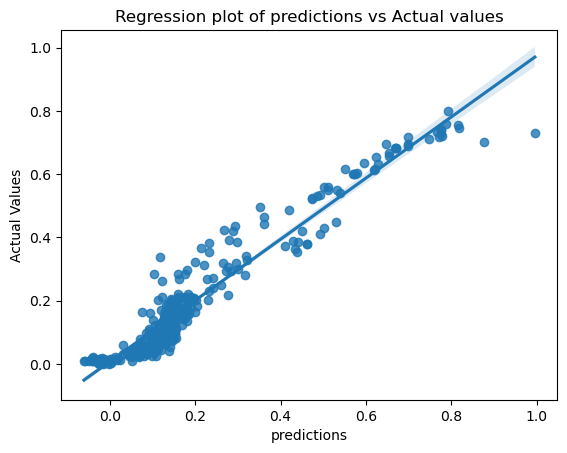

In [75]:
sns.regplot(x=y_pred,y=y_test)
plt.xlabel("predictions")
plt.ylabel("Actual Values")
plt.title("Regression plot of predictions vs Actual values")
plt.show()